# Compare Memory-Based versus Generator-Based Data Loading — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/06-computer-vision-capstone/notebooks/compare-memory-based-versus-generator-based-data-loading.ipynb) · [Course notes](../../../courses/06-computer-vision-capstone/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations. Dataset override: Reused locally cached course image archive and any available course weight files; full image archive retained, training remains bounded. Cached asset hashes are recorded; no historical outputs are imported.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<div style="text-align: center;">
  <a href="https://cognitiveclass.ai/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDL0321ENSkillsNetwork951-2022-01-01">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DL0321EN-SkillsNetwork/image/IDSN-logo.png" width="400">
  </a>
</div>



<h1 align=left><font size = 5>Compare Memory-Based versus Generator-Based Data Loading</font></h1>


<h5>Estimated time: 30 minutes</h5>


<h2>Learning objective</h2>
After completing this lab, you'll be able to:

- Download and manage satellite image datasets using Keras and Python libraries
- Compare memory-based and generator-based data loading strategies in terms of performance, memory efficiency, and implementation complexity
- Build a simple, memory-efficient image pipeline by loading and visualizing geospatial image data sequentially
- Assess the trade-offs between loading entire image datasets into memory versus accessing image paths on demand


## Introduction


Geospatial data analysis is a highly competitive and growing sector. It is used for land cover mapping, building roads, detection, and temporal land usage monitoring, among other applications. In this lab, you will learn to efficiently build a classifier by training a model from a curated dataset. For problem formulation, you will use images to denote agricultural land vs. non-agricultural land.

Additionally, you will learn to download a dataset from the cloud. The notebook will illustrate two common ways to work with image datasets in Python: Loading file paths and opening images one by one, which is sequential loading and holding all images in memory at once, which is bulk loading. You will learn how each approach affects code simplicity, memory use, and I/O performance.

**Note:** Throughout this lab, you’ll answer strategically placed questions designed to reinforce your learning and complete the quiz.


## Table of contents

<font size = 3>    

1. [Import libraries and packages](#Import-libraries-and-packages)
2. [Download data](#Download-data)
3. [Load images](#Load-images)

</font>
</div>


### Install the required libraries

All the required libraries are __not__ pre-installed in the Skills Network Labs environment. __You need to run the following cell__ to install them, and this might take a few minutes.


Install these dependencies into your Jupyter kernel before running this notebook: `numpy matplotlib pillow`.

The import cells below verify the notebook dependencies.

## Import libraries and packages


Let's begin by importing the libraries and packages that you will need to complete the rest of this lab.


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

Matplotlib is building the font cache; this may take a moment.


## Download data


The data is on a cloud server. You can retrieve and unzip it easily using the **skillsnetwork.prepare** command. So, let's run the following line of code to download the data. 


In [3]:
import os
from pathlib import Path
from shutil import copyfileobj
from urllib.request import urlopen

def download_course_asset(url, destination):
    destination = Path(destination)
    if destination.is_file():
        return destination
    temporary = destination.with_name(destination.name + '.part')
    try:
        with urlopen(url, timeout=90) as response, temporary.open('wb') as target:
            copyfileobj(response, target)
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination

def prepare_course_dataset(url, directory='.'):
    import tarfile
    directory = Path(directory)
    dataset = directory / 'images_dataSAT'
    if not dataset.is_dir():
        archive = download_course_asset(url, directory / 'images-dataSAT.tar')
        with tarfile.open(archive) as tar:
            tar.extractall(directory, filter='data')
    print('Dataset available at', dataset)
    return dataset
prepare_course_dataset('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/4Z1fwRR295-1O3PMQBH6Dg/images-dataSAT.tar', '.')

Dataset available at images_dataSAT


PosixPath('images_dataSAT')

Now, you will be able to see the **images_dataSAT** folder in the left pane. It has two folders  **class_0_non_agri** and **class_1_agri**.
The folder structure looks as follows:

```python
images_dataSAT/
├── class_0_non_agri/
└── class_1_agri/

```

<table>
    <tr>
        <td style="text-align:center;"><b>Primary folder</b></td>
        <td style="text-align:center;"><b>Subfolders</b></td>
    </tr>
    <tr>
        <td><img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/owykkC4Pr2zxLtU6vskQ5A/DL0321EN-M1L1-file-tree-Screenshot-1.png" style="width:300px; border:0px solid black;"></td>
        <td><img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/okqnadJpvAeedGUXXYBIFg/DL0321EN-M1L1-file-tree-Screenshot-2.png" style="width:350px; border:0px solid black;"></td>
    </tr>
</table>


**class_0_non_agri** is the non-agricultural land class, as defined earlier, and it represents images with non-cultivable land. 

**class_1_agri**, on the other hand, is the agricultural land class, and it represents the images with cultivable land.



<table>
    <tr>
        <td style="text-align:center;"><b>class_0_non_agri</b></td>
        <td style="text-align:center;"><b>class_1_agri</b></td>
    </tr>
    <tr>
        <td><img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/1jSl6X5tUkVro8I_av8lEQ/DL0321EN-M1L1-file-tree-screenshot-3.png" style="width:300px; border:1px solid black;"></td>
        <td><img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/9f7sT5DBeFE_6Mp2OV3JKQ/DL0321EN-M1L1-file-tree-screenshot-4.png" style="width:300px; border:1px solid black;"></td>
    </tr>
</table>


**Note:** There are a few thousand images in each folder, so don't double-click on the folders. This may consume all of your memory, and you may end up with a **50*** error.


## Load images


Next, you will use the standard approach of loading all images in memory and demonstrate how this approach is not efficient when it comes to building deep learning models for classifying images.


In [4]:
extract_dir = '.'
base_dir = os.path.join(extract_dir, 'images_dataSAT')
dir_non_agri = os.path.join(base_dir, 'class_0_non_agri')
dir_agri = os.path.join(base_dir, 'class_1_agri')

Let's start by reading in the non_agri images. First, you will use **os.scandir** to build an iterator to iterate through the *./images_dataSAT/class_0_non_agri* directory, which contains all the images with non-agriculture land.
Display the first 5 entries in the non_agri list 


In [5]:
non_agri = os.scandir(dir_non_agri)
for f_path in range(5):
    print(next(non_agri))

<DirEntry 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UQB_20250427T170513.SAFE_25907.jpg'>
<DirEntry 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UPE_20250427T170513.SAFE_25984.jpg'>
<DirEntry 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UQB_20250427T170513.SAFE_15608.jpg'>
<DirEntry 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UQB_20250427T170513.SAFE_3487.jpg'>
<DirEntry 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UQB_20250427T170513.SAFE_14258.jpg'>


Then, you will grab the first file in the directory.


In [6]:
file_name = next(non_agri)
file_name

<DirEntry 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UPE_20250427T170513.SAFE_25012.jpg'>

Since the directory can contain elements that are not files, you only need to read the element if it is a file.


In [7]:
os.path.isfile(file_name)

True

Get the image name.


In [8]:
image_name = str(file_name).split("'")[1]
image_name

'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UPE_20250427T170513.SAFE_25012.jpg'

Read within the image data.


In [9]:
image_data = plt.imread(os.path.join(dir_non_agri, image_name))
image_data

array([[[ 86,  55,  63],
        [ 88,  57,  65],
        [104,  74,  82],
        ...,
        [ 95,  74,  79],
        [100,  79,  84],
        [ 76,  55,  60]],

       [[117,  86,  94],
        [109,  78,  86],
        [103,  73,  81],
        ...,
        [150, 129, 134],
        [153, 132, 137],
        [154, 133, 138]],

       [[159, 128, 136],
        [151, 120, 128],
        [135, 105, 113],
        ...,
        [216, 193, 199],
        [213, 190, 196],
        [241, 218, 224]],

       ...,

       [[ 29,  35,  21],
        [ 29,  35,  21],
        [ 31,  35,  21],
        ...,
        [127, 100, 105],
        [132, 105, 110],
        [123,  96, 101]],

       [[ 34,  40,  26],
        [ 33,  39,  25],
        [ 33,  37,  23],
        ...,
        [ 89,  62,  67],
        [ 95,  68,  73],
        [142, 115, 120]],

       [[ 25,  31,  17],
        [ 25,  31,  17],
        [ 26,  30,  16],
        ...,
        [112,  85,  90],
        [100,  73,  78],
        [ 94,  67,  72]]

### **Question 1**: What are the dimensions of a single image according to **image_data**? 


In [10]:
print(f'Single image shape (height, width, channels): {image_data.shape}')

Single image shape (height, width, channels): (64, 64, 3)


Double-click **here** for the solution.
<!--
print(image_data.shape)
-->


Let's take a look at the image.


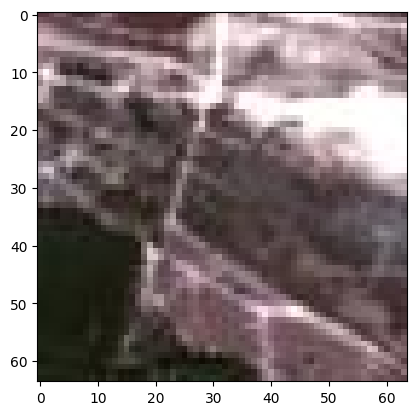

In [11]:
plt.imshow(image_data)

Now that you are familiar with the process of reading image data, let's loop through all the images in the *./images_dataSAT/class_0_non-agri* directory, read them all, and save them in the list **non_agri_images**. You will also need to note how long it takes to read all the images.


In [12]:
non_agri_images = []
for file_name in non_agri:
    if os.path.isfile(file_name):
        image_name = str(file_name).split("'")[1]
        image_data = plt.imread(os.path.join(dir_non_agri, image_name))
        non_agri_images.append(image_data)
non_agri_images = np.array(non_agri_images)

Loading images into memory is not the right approach when working with images, as it takes a long time or can quickly exhaust memory and other resources. Therefore, let's repeat the previous process but save the paths to the images in a variable instead of loading and saving the individual images.


So, instead of using **os.scandir**, let's use **os.listdir**.


In [13]:
non_agri_images = os.listdir(dir_non_agri)
non_agri_images[:5]

['tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UQB_20250427T170513.SAFE_25907.jpg',
 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UPE_20250427T170513.SAFE_25984.jpg',
 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UQB_20250427T170513.SAFE_15608.jpg',
 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UQB_20250427T170513.SAFE_3487.jpg',
 'tile_S2A_MSIL2A_20250427T101701_N0511_R065_T32UQB_20250427T170513.SAFE_14258.jpg']

Notice how the images are not sorted, so let's call the <code>sort</code> method to sort the images.


In [14]:
non_agri_images.sort()
non_agri_images[:5]

['tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_5902.jpg',
 'tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_6074.jpg',
 'tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_6246.jpg',
 'tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_6247.jpg',
 'tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_6248.jpg']

Before you can show an image, you need to open it. You can do this by using the **Image** module in the **PIL** library. To open the first image, run the following:


In [15]:
image_data = Image.open(os.path.join(dir_non_agri, non_agri_images[0]))

To view the image, run:


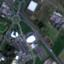

In [16]:
image_data

or use the <code>plt.imshow()</code> method as follows:


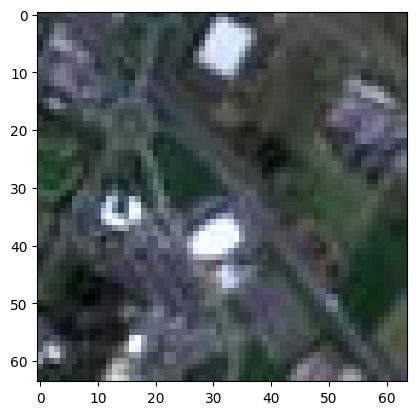

In [17]:
plt.imshow(image_data)

Let's loop through all the images in the <code>'./images_dataSAT/class_0_non_agri/'</code> directory and add their paths.


In [18]:
non_agri_images_paths = [os.path.join(dir_non_agri, image) for image in non_agri_images]
non_agri_images_paths[:5]

['./images_dataSAT/class_0_non_agri/tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_5902.jpg',
 './images_dataSAT/class_0_non_agri/tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_6074.jpg',
 './images_dataSAT/class_0_non_agri/tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_6246.jpg',
 './images_dataSAT/class_0_non_agri/tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_6247.jpg',
 './images_dataSAT/class_0_non_agri/tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_6248.jpg']

Let's check how many images of non-agricultural land exist in the dataset.


In [19]:
len(non_agri_images_paths)

3000

### Question 2: Display the first four images in `'./images_dataSAT/class_0_non_agri/'` directory.


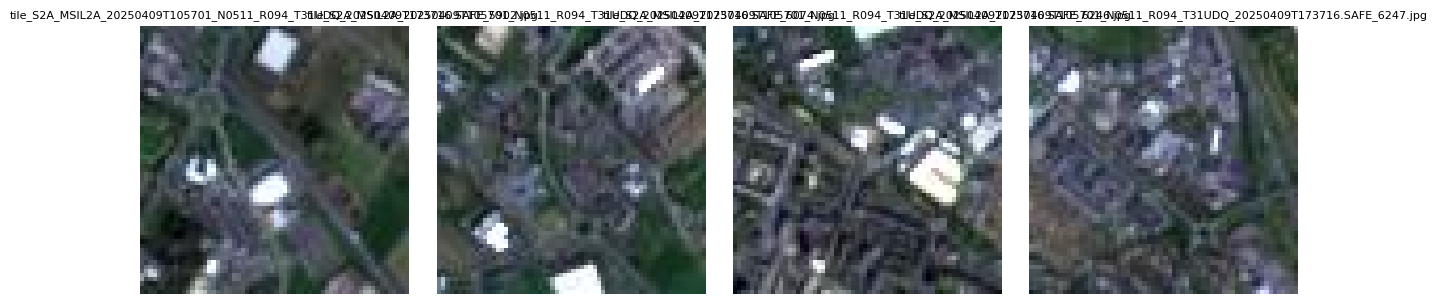

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, filename in zip(axes, non_agri_images[:4]):
    with Image.open(os.path.join(dir_non_agri, filename)) as image:
        ax.imshow(image)
    ax.set_title(filename, fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

Double-click **here** for the solution.
<!--
n_images = 4
for image_path in non_agri_images[:n_images]:
    print(image_path)
    image_data = Image.open(os.path.join(dir_non_agri, image_path))
    plt.imshow(image_data)
    plt.show()
-->


### **Task 1**: 
Save the paths to all the images in the `dir_agri` directory in a list called **agri_images_paths**. Make sure you sort the paths at the end.


In [21]:
from pathlib import Path
agri_images_paths = sorted((str(path.resolve()) for path in Path(dir_agri).iterdir() if path.is_file() and path.suffix.lower() in {'.jpg', '.jpeg', '.png'}))
agri_images_path = agri_images_paths
print('First agricultural filenames:', [Path(path).name for path in agri_images_paths[:3]])
assert all((Path(path).is_absolute() for path in agri_images_paths))

First agricultural filenames: ['tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_5878.jpg', 'tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_5884.jpg', 'tile_S2A_MSIL2A_20250409T105701_N0511_R094_T31UDQ_20250409T173716.SAFE_6628.jpg']


Double-click **here** for the solution.
<!--
agri_images_paths = []
for image in os.listdir(dir_agri):
    agri_images_paths.append(os.path.join(dir_agri, image))

agri_images_paths.sort()
-->


### Question 3: How many images of agricultural land exist in the <code>'./images_dataSAT/class_1_agri/'</code> directory?


In [22]:
print(f'Agricultural land images: {len(agri_images_paths):,}')

Agricultural land images: 3,000


Double-click **here** for the solution.
<!--
print(len(agri_images_paths))
-->


### Question 4: Display the first four images of the agricultural land.


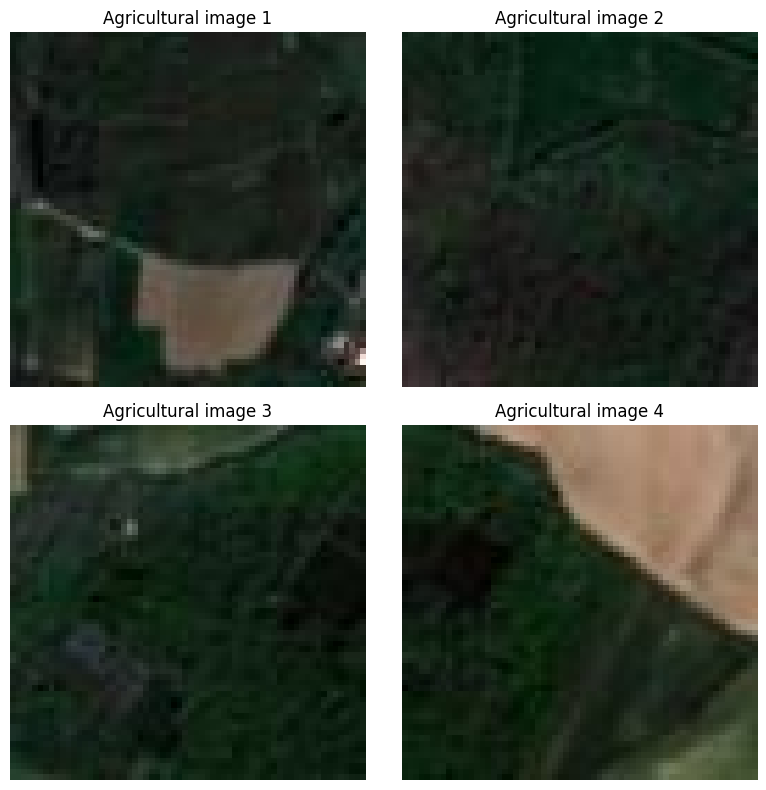

In [23]:
first_agri_images = agri_images_paths[:4]
assert len(first_agri_images) == 4
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for index, (ax, image_path) in enumerate(zip(axes.flat, first_agri_images), start=1):
    with Image.open(image_path) as image:
        ax.imshow(image)
    ax.set_title(f'Agricultural image {index}')
    ax.axis('off')
plt.tight_layout()
plt.show()

Double-click **here** for the solution.
<!--
n_images = 4
for image_path in agri_images_paths[:n_images]:
    print(image_path)
    image_data = Image.open(image_path)
    plt.imshow(image_data)
    plt.show()
-->


## Save and download the notebook for **final project** submission and evaluation

You will need to save and download the completed notebook for final project submission and evaluation. 
<br>For saving and downloading the completed ntoebook, please follow the steps given below:</br>

<font size = 4>  

1) **Complete** all the tasks and questions given in the notebook.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/nv4jHlPU5_R1q7ZJrZ69eg/DL0321EN-M1L1-Save-IPYNB-Screenshot-1.png" style="width:600px; border:0px solid black;">

2) **Save** the notebook.</style>
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/9-WPWD4mW1d-RV5Il5otTg/DL0321EN-M1L1-Save-IPYNB-Screenshot-2.png" style="width:600px; border:0px solid black;">

3) Identify and right click on the **correct notebook file** in the left pane.</style>
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/RUSRPw7NT6Sof94B7-9naQ/DL0321EN-M1L1-Save-IPYNB-Screenshot-3.png" style="width:600px; border:0px solid black;">

4) Click on **Download**.</style>
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/HHry4GT-vhLEcRi1T_LHGg/DL0321EN-M1L1-Save-IPYNB-Screenshot-4.png" style="width:600px; border:0px solid black;">

5) Download and **Save** the Jupyter notebook file on your computer **for final submission**.</style>
<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/hhsJbxc6R-T8_pXQGjMjvg/DL0321EN-M1L1-Save-IPYNB-Screenshot-5.png" style="width:600px; border:0px solid black;">
  </font>


### Congratulations!
You have successfully completed this lab. 


### Summary

This notebook shows a memory-efficient and simple sequential loading pattern by sorting and indexing filenames and then opening images one by one. To compare, you can try a bulk-loading approach by reading all images into a single list of arrays to observe the trade-off between faster repeated access and higher memory usage.


### Thank you for completing this lab!

This notebook is part of an IBM course on **Coursera** called *AI Capstone Project with Deep Learning*.


<h2>Author</h2>

[Aman Aggarwal](https://www.linkedin.com/in/aggarwal-aman)

Aman Aggarwal is a PhD working at the intersection of neuroscience, AI, and drug discovery. He specializes in quantitative microscopy and image processing.


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2025-06-25  | 1.0  | Aman  |  Created the lab |
| 2025-06-30  | 2.0  | Gagandeeep |  ID review |

-->


© Copyright IBM Corporation. All rights reserved.
